# Liner Regression and Logistic Regression (Part 2)

## Linear regression

- Least squares. $\beta_j$ is how much the outcome changes when $x_j$ goes up by one unit and the other inputs stay the same.
- Chapter 12. Open each lab and use the controls. Nothing in this part is fitted in the notebook.

### Dummies and interactions

- [Dummies and interactions lab](https://vsokolov.org/labs/interactions-lab.html). Orange-juice sales against price, for three brands, in weeks with and without an in-store ad.
- Sales and price are both in logs. The slope is then a percent: how many percent sales change when price changes by 1%.

$$
\log(\mathrm{sales}) = \beta_0 + \beta_1 \log(\mathrm{price}) + \varepsilon.
$$

- A dummy is 1 for its group and 0 for the others. The pair below is Minute Maid, then Tropicana. Dominick's is the comparison brand, so both numbers are 0. The ad is a separate 0-or-1 variable, 0 in a week with no ad. Every other number in the fit is a gap from Dominick's with no ad.

$$
\begin{aligned}
\text{Dominick's} &\colon (0,\, 0), & \text{Minute Maid} &\colon (1,\, 0), & \text{Tropicana} &\colon (0,\, 1).
\end{aligned}
$$

- Price only: one line for all three brands. A 1% higher price comes with about 1.5% lower sales. Tropicana costs more and sells more, so this one slope mixes price with brand.
- Add the brand dummies. Three parallel lines. Inside one brand, a 1% higher price now comes with about 3% lower sales.

$$
\log(\mathrm{sales}) = \beta_0 + \beta_1 \log(\mathrm{price}) + \beta_2 \,\mathrm{MM} + \beta_3 \,\mathrm{Trop}.
$$

- On the real Dominick's data that fit is $10.829 - 3.139\,\log(\mathrm{price}) + 0.870\,\mathrm{MM} + 1.530\,\mathrm{Trop}$.
- The Tropicana number is about $1.53$. At the same price, Tropicana sells about $e^{1.53}\approx 4.6$ times as much as Dominick's.
- Multiply a brand dummy by $\log(\mathrm{price})$ and that brand gets its own slope. $\beta_5$ is Tropicana's percent response to price, minus Dominick's.

$$
\log(\mathrm{sales}) = \beta_0 + \beta_1 \log(\mathrm{price}) + \beta_2 \,\mathrm{MM} + \beta_3 \,\mathrm{Trop} + \beta_4 \,\mathrm{MM}\cdot\log(\mathrm{price}) + \beta_5 \,\mathrm{Trop}\cdot\log(\mathrm{price}).
$$

- Let the ad change the slope. With no ad the slope is $\beta_1$. In an advertised week it is $\beta_1+\beta_3$.

$$
\log(\mathrm{sales}) = \beta_0 + \beta_1 \log(\mathrm{price}) + \beta_2 \,\mathrm{feat} + \beta_3 \,\log(\mathrm{price})\cdot\mathrm{feat}.
$$

- On the real data that fit is $9.659 - 0.958\,\log(\mathrm{price}) + 1.714\,\mathrm{feat} - 0.977\,\log(\mathrm{price})\cdot\mathrm{feat}$. Rounded, a 1% price rise cuts sales by 0.96% with no ad and by 1.94% when the juice is advertised.
- With thousands of store-weeks, a tiny price response can still have a $t$ above 2. Ask whether a gap of 0.05 would change the price the store charges.

### The election forecast

- [Election forecast lab](https://vsokolov.org/labs/election-lab.html). Ray Fair's vote equation, 27 US presidential elections, 1916 to 2020.
- The outcome is the Democratic share of the two-party popular vote. $I=1$ when a Democrat is president, and $I=-1$ when a Republican is.
- Growth and the Democratic share move together only weakly: correlation $0.20$. Growth and the share of whoever is president move together strongly: correlation $0.73$. 1964 and 1984 were both strong economies, one under a Democrat and one under a Republican, so on a plot of the Democratic share they point opposite ways.
- $0.20$: growth barely tracks the Democratic share. $0.73$: it tracks the share of the party in office. A strong economy helps whoever is president.
- Multiply growth, inflation, and the good-news count by $I$. Each then needs only one number in the equation, $0.69$, $-0.73$, and $0.67$. The sign of $I$ turns that number from a help for Democrats into a help for Republicans. There is no second number for the other party.
- Fit the Democratic share on growth, inflation, and good news alone and you explain 4% of the variation. Multiply those three by $I$ and you explain 68%. Add whether the president is running again, and how long the party has held office, and you reach 84%.
- The chosen equation, fit to 1916--2020. VP is the Democratic share of the two-party popular vote, in percent:

$$
\widehat{\mathrm{VP}} = 48.52 + 2.82\,\mathrm{DPER} - 2.78\,\mathrm{DUR} + 0.69\, G\cdot I - 0.73\, P\cdot I + 0.67\, Z\cdot I.
$$

- DPER is 1 if the Democratic president runs again, $-1$ if the Republican president runs, and 0 if neither does. A Democrat running again adds about 2.8 points to the Democratic share.
- DUR says how long that party has already been in office. It is 0 after one term, then 1, 1.25, and 1.5 after two, three, and four terms. Put a minus sign on it when the Republicans are the party that held office. The equation multiplies that number by $-2.78$. Two Democratic terms, DUR $=1$, take 2.78 points off the Democratic share. Two Republican terms, DUR $=-1$, add 2.78 points to it.
- $G$ is growth in real income per person in the first three quarters of the election year, in percent per year. One extra point of growth adds 0.69 points to the share of the party in office.
- $P$ is inflation over the first 15 quarters of the term, in percent per year. It is set to 0 in a war year. Inflation hurts the party in office: the number on $P\cdot I$ is $-0.73$.
- $Z$ counts how many of those 15 quarters had real income per person growing faster than 3.2% a year. It is set to 0 for the war elections of 1920, 1944, and 1948. One extra such quarter adds 0.67 points to the share of the party in office.
- The typical miss is $\hat\sigma = 2.96$ percentage points, with 21 observations left over after the fit. The measures that penalize extra variables all choose this equation. Adding $I$ on its own, or a 0-or-1 marker for the war elections, does not help once DPER and DUR are already in. $I$ is already inside $G\cdot I$, $P\cdot I$, and $Z\cdot I$.
- A forecast is a number, a range, and a chance. For 2024 the equation gave 46.1, a 95% range of about 38.2 to 54.1, and a 0.16 chance that the Democratic share would top 50. The share was 49.25, so the forecast missed by 3.1 points and the range still covered the result.
- The width of that range combines two uncertainties: where the line sits, and how far a new election falls off the line. In the formula $\hat\sigma\sqrt{1+h_0}$, the $h_0$ says how unusual the new election's inputs are compared with 1916--2020.
- VP is the national popular vote, not the state-by-state result that decides the presidency. In 2016 the Democrats won 51.2% of the two-party vote and lost the White House.
- Twenty-seven elections and six numbers in the fit, so one election can move a number. The typical error on the elections used to fit the line is 2.6 points. Leaving one election out and predicting it gives 3.4. Fitting only on earlier elections and then forecasting the next one gives 3.7.

### Lessons

- A strong economy helps whoever is president, so growth barely follows the Democratic share and closely follows the share of the party in office. Multiply growth, inflation, and the good-news count by $I$ and the same three go from explaining 4% to explaining 68%. Growth has one number, $0.69$. One extra point of growth adds $0.69$ points to the Democratic share when a Democrat is president ($I=1$) and takes $0.69$ points off it when a Republican is president ($I=-1$). Inflation ($-0.73$) and the good-news count ($0.67$) flip the same way. There is no second number for the other party.
- The equation forecasts the Democratic share of the national two-party popular vote, in percent. It does not forecast the Electoral College. In 2016 the Democrats won 51.2% of that popular vote and lost the presidency.
- For 2024 the equation gave 46.1, a 95% range of about 38.2 to 54.1, and a 0.16 chance that the Democratic share would top 50. The share was 49.25, a miss of 3.1 points, and that result sits inside the range.
- There are 27 elections and six numbers in the fit. The typical error is 2.6 points on the elections used to draw the line. Leaving one election out and predicting it gives 3.4. Drawing the line only from earlier elections, then forecasting the next one, gives 3.7.


## Logistic Regression

- Logistic regression is for a yes-or-no outcome. The log of the odds is a straight-line function of the inputs,

$$
\log\frac{p}{1-p} = \beta^\top x, \qquad p = \frac{1}{1+e^{-\beta^\top x}}.
$$

- The fit is the one that makes the observed yes-or-no answers as likely as possible. On one answer the penalty is $-\log p$ for the answer that happened.
- Two answers. Softmax is the same idea with $K$ answers. A cutoff $t$ turns the probability into a yes or a no.
- Tennis, then German credit. The ROC curve and the cutoff are introduced on the loans.
- Softmax: the formula, three classes in the plane, then the next word.
- The kernel trick.
- Betting: the odds, the favorite, the stake.
- In the Benter lab, $\alpha$ stretches the public probabilities. The cutoff in this notebook is $t$. The book uses $\alpha$ for that cutoff.
- [Dummies and interactions](https://vsokolov.org/labs/interactions-lab.html). [Election forecast](https://vsokolov.org/labs/election-lab.html). [Benter lab](https://vsokolov.org/labs/benter-lab.html). [Logistic regression lab](https://vsokolov.org/labs/logistic-roc-lab.html). [Next-token lab](https://vsokolov.org/labs/next-token-lab.html).
- The first cell downloads `tennis.csv`, `credit.csv`, and `hkjc-favorites.csv` into `data/`.
- Guess before you run the cell.


In [2]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

DATA = Path('data')
DATA.mkdir(exist_ok=True)
BASE = 'https://vsokolov.org/courses/files/600/data'
for name in ('tennis.csv', 'credit.csv', 'hkjc-favorites.csv'):
    path = DATA / name
    if not path.exists():
        urlretrieve(f'{BASE}/{name}', path)

## 1. Tennis

- Four majors, 2013. 943 matches. `Result` is 1 when player 1 won.
- `BPW.1` and `BPW.2` are break points won. One match has none. The cell drops it.
- A dot breaks the formula, so the columns become `BPW1` and `BPW2`.

In [3]:
tennis = pd.read_csv(DATA / 'tennis.csv')
tennis = tennis.dropna(subset=['BPW.1', 'BPW.2']).copy()
# A dot in a name breaks the formula parser, so the chapter's BPW.1 and BPW.2 are BPW1 and BPW2 from here.
tennis = tennis.rename(columns={'BPW.1': 'BPW1', 'BPW.2': 'BPW2'})
print(f"{len(tennis)} matches, {tennis.shape[1]} columns")
print(tennis.gender.value_counts().to_dict())
print(tennis.surf.value_counts().to_dict())
tennis[['Player1', 'Player2', 'Round', 'Result', 'gender', 'surf', 'BPW1', 'BPW2']].sample(5, random_state=11)


942 matches, 44 columns
{'M': 491, 'W': 451}
{'Hard': 454, 'Clay': 252, 'Grass': 236}


,Player1,Player2,Round,Result,gender,surf,BPW1,BPW2
366,Tommy Robredo,Nicolas Almagro,4,1,M,Clay,20.0,13.0
66,Sam Querrey,Ernests Gulbis,2,1,M,Hard,9.0,3.0
448,Anna Karolina Schmiedlova,Jamie Hampton,2,0,W,Clay,2.0,13.0
828,J.Jankovic,J.Konta,1,1,W,Grass,3.0,0.0
587,Alex Bogomolov Jr.,Tim Smyczek,1,0,M,Hard,14.0,16.0


### Break points and the winner

In [3]:
# Scatter BPW1 against BPW2, with the marker set by Result.

- Plot `BPW1` against `BPW2`. Mark player 1's wins differently from player 1's losses.
- A player has to win break points to win the match, so player 1's wins sit toward the `BPW1` axis and player 2's wins toward the `BPW2` axis.
- Before you look: which corner is player 1's wins?
- After the plot: which corner holds player 1's wins, and were you right?
- Where do the two marks overlap? Pick one of those matches and read off the two break-point counts.


### The fit

In [4]:
# model = smf.logit('Result ~ BPW1 + BPW2 - 1', data=tennis).fit()

- Fit `Result ~ BPW1 + BPW2 - 1`.
- The log of the odds is a straight line, with no intercept:

$$
\log\frac{p}{1-p} = \beta_1 \,\mathrm{BPW1} + \beta_2 \,\mathrm{BPW2}.
$$

- One extra break point for player 1, with player 2's count held at 0, multiplies player 1's odds of winning by $e^{\beta_1}$.
- Compute that factor, and $p$ at $(0,0)$, $(1,0)$, and $(3,0)$.
- The two numbers should be about the same size and opposite in sign. A break point won by player 2 is the mirror of one won by player 1.
- Read $\beta_1$ and $\beta_2$. Are they about the same size and opposite in sign?
- Why is $p$ at $(0,0)$ equal to $1/2$?


### A cutoff of one half

In [5]:
model = smf.logit('Result ~ BPW1 + BPW2 - 1', data=tennis).fit(disp=0)
picked = (model.predict(tennis) > 0.5).astype(int)
pd.crosstab(tennis.Result.rename('won'), picked.rename('picked'))


picked,0,1
won,,
0,416,61
1,65,400


- The table above is the confusion matrix. Rows are who won. Columns are who the model picked, at $t=0.5$.
- Accuracy is the share of matches in the two correct cells.
- The line $p=1/2$ is $\beta_1 x_1 + \beta_2 x_2 = 0$. Draw it on the scatter.
- What share of the matches are in the two correct cells?
- Of the two wrong cells, which has more matches?


### Are women's matches less predictable?

In [6]:
# res = np.abs(model.resid_dev)
# Box plot of res by gender. Drop residuals of 2 or more.


- The residual is how far the fit missed that match. A larger absolute residual is a worse prediction.
- Draw a box plot of the absolute residual for men and for women. Leave out residuals of 2 or more.
- Which box has the higher line in the middle?
- Does the plot support the claim that women's matches are less predictable?


### One more cut of the same matches

Repeat the box plot on one split you choose: surface (`Hard`, `Clay`, `Grass`) or round. Say what would change your mind about that split.


In [7]:
# Your split.

- Repeat the box plot on surface (`Hard`, `Clay`, `Grass`) or on round.
- Say what would change your mind about that split.
- Which group has the higher line in the middle?
- Is that gap larger than the gap between men and women?


## 2. German credit

- 1,000 German loans. 300 were not repaid.
- `history` is collapsed to good, poor, or terrible. `purpose` is collapsed to new car, used car, goods or repair, education, or business.
- `foreign` is 1 for a foreign worker. `rent` is 1 when the applicant rents.
- The model includes each of these on its own, and every product of two of them: duration, amount, installment, age, history, purpose, foreign, and rent.
- The comparison groups are good history, a new car, a foreign worker, and not renting. Each fitted number is the gap from that group, with the other inputs held the same.
- Some columns can be built from the others, so they are dropped. 71 terms remain.


In [ ]:
import warnings

import patsy
import statsmodels.api as sm
from scipy.linalg import qr

credit = pd.read_csv(DATA / 'credit.csv')
credit['history'] = pd.Categorical(
    credit['history'].map({'A30': 'good', 'A31': 'good', 'A32': 'poor', 'A33': 'poor', 'A34': 'terrible'}),
    ['good', 'poor', 'terrible'])
credit['purpose'] = pd.Categorical(
    credit['purpose'].map({
        'A40': 'newcar', 'A41': 'usedcar',
        'A42': 'goods_repair', 'A43': 'goods_repair', 'A44': 'goods_repair', 'A45': 'goods_repair',
        'A46': 'edu', 'A48': 'edu', 'A49': 'biz', 'A410': 'biz'}),
    ['newcar', 'usedcar', 'goods_repair', 'edu', 'biz'])
credit['foreign'] = pd.Categorical(
    credit['foreign'].map({'A201': 'foreign', 'A202': 'german'}), ['foreign', 'german'])
credit['rent'] = pd.Categorical(np.where(credit.housing.eq('A151'), 'yes', 'no'), ['no', 'yes'])
print(f"{len(credit)} loans, {int(credit.Default.sum())} defaults")
print(credit.head())



y, X = patsy.dmatrices(
    'Default ~ (duration + amount + installment + age + C(history) + C(purpose) + C(foreign) + C(rent))**2',
    credit, return_type='dataframe')
values = np.asarray(X, float)
_, r, piv = qr(values, pivoting=True, mode='economic')
diag = np.abs(np.diag(r))
rank = int(np.sum(diag > 1e-8 * diag[0]))
Xr = X.iloc[:, np.sort(piv[:rank])]

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    full = sm.Logit(np.asarray(y).ravel(), Xr).fit(disp=0, maxiter=100)

table = pd.DataFrame({
    'coef': full.params,
    'std_err': full.bse,
    'z': full.tvalues,
    'p': full.pvalues,
}).sort_values('p')
print(f"{Xr.shape[1]} terms, AIC {full.aic:.1f}, p < 0.1: {(table.p < 0.1).sum()}")
table.round(4)

   Default checkingstatus1  duration   history       purpose  amount savings  \
0        0             A11         6  terrible  goods_repair    1169     A65   
1        1             A12        48      poor  goods_repair    5951     A61   
2        0             A14        12  terrible           edu    2096     A61   
3        0             A11        42      poor  goods_repair    7882     A61   
4        1             A11        24      poor        newcar    4870     A61   

  employ  installment status  ... property  age otherplans  housing cards  \
0    A75            4    A93  ...     A121   67       A143     A152     2   
1    A73            2    A92  ...     A121   22       A143     A152     1   
2    A74            2    A93  ...     A121   49       A143     A152     1   
3    A74            2    A93  ...     A122   45       A143     A153     1   
4    A73            3    A93  ...     A124   53       A143     A153     2   

    job  liable  tele  foreign rent  
0  A173       1  A

,coef,std_err,z,p
duration:C(history)[T.terrible],0.1069,0.0376,2.8422,0.0045
C(purpose)[T.usedcar],-8.4015,3.0309,-2.7720,0.0056
age:C(purpose)[T.biz],0.0700,0.0280,2.4988,0.0125
amount:C(purpose)[T.usedcar],0.0003,0.0002,2.2467,0.0247
duration:amount,-0.0000,0.0000,-2.1865,0.0288
...,...,...,...,...
amount:C(history)[T.poor],-0.0000,0.0001,-0.1463,0.8837
C(history)[T.poor]:C(purpose)[T.biz],0.1069,0.9763,0.1095,0.9128
C(purpose)[T.usedcar]:C(rent)[T.yes],0.0857,1.1570,0.0741,0.9409
installment:C(rent)[T.yes],0.0067,0.2249,0.0298,0.9762


- Keep a term if its p-value in this table is below 0.1. That is the rule in the homework.
- The intercept is kept only if its own p-value is below 0.1.


In [9]:
# keep = table.index[table.p < 0.1]
# reduced = sm.Logit(np.asarray(y).ravel(), Xr[keep]).fit(disp=0)

- Fit again, using only those columns.
- Write down both AIC values.
- List the terms whose p-value moves from below 0.1 to above it.
- A term can look useful in the large model and useless in the model that keeps only the survivors.
- Which model has the higher AIC, and by how much? The higher AIC is the worse description of these loans.
- How many of the kept terms still have $p < 0.1$? Did the intercept stay?


t = 0.2: sensitivity 0.880, false positive rate 0.519
t = 0.5: sensitivity 0.377, false positive rate 0.074


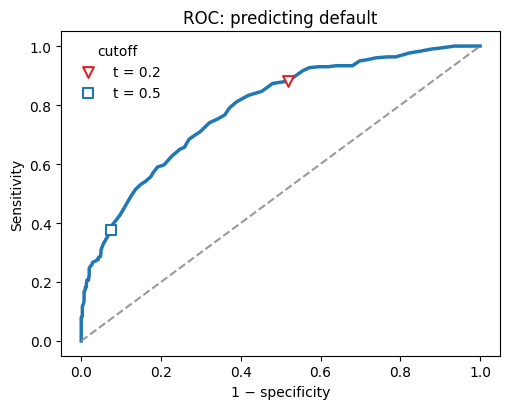

In [10]:
def roc(p, y, n_grid=100):
    p = np.asarray(p, dtype=float)
    y = np.asarray(y)
    grid = np.linspace(0, 1, n_grid)
    call = p[:, None] > grid[None, :]
    specificity = np.mean(~call[y == 0], axis=0) if np.any(y == 0) else np.ones(n_grid)
    sensitivity = np.mean(call[y == 1], axis=0) if np.any(y == 1) else np.zeros(n_grid)
    return grid, sensitivity, specificity

def roc_point(p, y, t):
    y = np.asarray(y)
    false_positive = 1 - np.mean(p[y == 0] < t)
    sensitivity = np.mean(p[y == 1] > t)
    return false_positive, sensitivity

# Positive class: the loan defaults. Predict default when p > t.
p_default = np.asarray(full.predict(Xr))
default = credit.Default.to_numpy()
grid, sensitivity, specificity = roc(p_default, default)

fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.plot(1 - specificity, sensitivity, color='C0', lw=2.5)
ax.plot([0, 1], [0, 1], color='0.6', ls='--')
for t_mark, marker, color in ((0.2, 'v', 'C3'), (0.5, 's', 'C0')):
    x, sens = roc_point(p_default, default, t_mark)
    ax.scatter([x], [sens], marker=marker, s=60, facecolors='white', edgecolors=color, linewidths=1.5, label=f't = {t_mark}', zorder=3)
    print(f't = {t_mark}: sensitivity {sens:.3f}, false positive rate {x:.3f}')
ax.set_xlabel('1 − specificity')
ax.set_ylabel('Sensitivity')
ax.set_title('ROC: predicting default')
ax.legend(frameon=False, title='cutoff')
fig.tight_layout()

Specificity

$$
\mathrm{Specificity} = \frac{\text{repaid loans the rule calls repaid}}{\text{repaid loans}}.
$$

Sensitivity

$$
\mathrm{Sensitivity} = \frac{\text{defaults the rule catches}}{\text{defaults}}.
$$

- One cutoff is one point on the curve.
- Sensitivity: of the loans that defaulted, the share this rule catches.
- The horizontal axis: of the loans that were repaid, the share this rule wrongly calls defaults.
- Lowering $t$ moves up and to the right. More defaults caught, more good loans refused.
- The diagonal is a useless rule: it does no better than ignoring the loan.
- The costs pick the cutoff. The curve says whether any cutoff is worth using.
- Making the loan gains \$0.25 per dollar if it is repaid and loses the dollar if it defaults.

$$
0.25(1-p) - 1\cdot p = 0.25 - 1.25p.
$$

- That value is positive when $p < 1/5$. Lend when the chance of default is below 0.2. That is the red point. A cutoff of 0.5 does not match these costs.
- Turning down a loan that would have been repaid gives up 0.25. Missing a default costs 1. Those two costs are why the cutoff is $1/5$ rather than $1/2$.
- Accuracy is the wrong summary. A rule that never predicts default is already right on 700 of the 1,000 loans.


## 3. Softmax

### Three classes in the plane


accuracy 1.000
probabilities at (0, 0.8): [[0.905 0.047 0.047]]


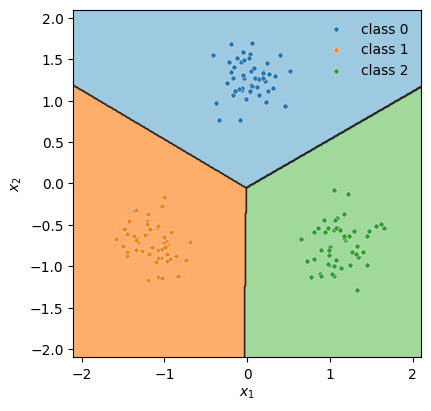

In [8]:
from sklearn.linear_model import LogisticRegression

rng = np.random.default_rng(2)
centers = np.array([[0.0, 1.3], [-1.15, -0.7], [1.15, -0.7]])
X3 = np.vstack([rng.normal(loc=c, scale=0.22, size=(50, 2)) for c in centers])
y3 = np.repeat([0, 1, 2], 50)
three = LogisticRegression().fit(X3, y3)
print(f'accuracy {three.score(X3, y3):.3f}')
print('probabilities at (0, 0.8):', np.round(three.predict_proba([[0.0, 0.8]]), 3))

grid = np.linspace(-2.1, 2.1, 400)
xx, yy = np.meshgrid(grid, grid)
regions = three.predict(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(4.4, 4.4))
ax.contourf(xx, yy, regions, levels=[-0.5, 0.5, 1.5, 2.5], colors=['#9ecae1', '#fdae6b', '#a1d99b'])
ax.contour(xx, yy, regions, levels=[0.5, 1.5], colors='0.15', linewidths=1.2)
for k, color, name in ((0, 'C0', 'class 0'), (1, 'C1', 'class 1'), (2, 'C2', 'class 2')):
    ax.scatter(X3[y3 == k, 0], X3[y3 == k, 1], s=14, c=color, edgecolors='white', linewidths=0.3, label=name)
ax.set_aspect('equal')
ax.set_xlabel(r'$x_1$')
ax.set_ylabel(r'$x_2$')
ax.legend(frameon=False)
fig.tight_layout()


- $K$ classes. One score $z_k$ per class. Softmax turns the scores into probabilities that sum to 1:

$$
p_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}.
$$

- Subtract the largest score before taking $e^{z}$. The probabilities stay the same, and the calculation does not overflow.
- The scores do not have to sum to 1. The probabilities do.
- The penalty is $-\log p$ for the class that happened.
- With two classes, set one score to 0. Softmax then becomes the logistic formula above.
- The predicted class is the one with the largest probability.


- One straight line cannot separate all three clouds.
- Each class has its own straight-line score, $\omega_k^\top x + b_k$.
- The border between class $j$ and class $k$ is where those two scores are equal, and both are larger than the third.
- The three borders meet at one point.
- Every point here is classified correctly. At $(0, 0.8)$, in the top cloud, the three probabilities are about 0.90, 0.05, and 0.05.


### The next word is the same softmax

- A language model gives a probability for every possible next piece of text, given the pieces already written.
- A token is a word, a piece of a word, or a character.
- Here the classes are the words that have followed the current word. The score of a word is the log of how often it followed.
- The book's prompt is "The best thing about AI is its ability to". The corpus here is six sentences you can count by hand.
- Then open the [next-token lab](https://vsokolov.org/labs/next-token-lab.html). Temperature divides the scores before the softmax, which flattens or sharpens the probabilities. Top-$k$ keeps the $k$ most likely tokens. Top-$p$ keeps the smallest set of top tokens whose probabilities add up to at least $p$. What remains is scaled so the probabilities sum to 1.


In [13]:
from collections import Counter

lines = [
    'the model learns from data .',
    'the model learns from data .',
    'the model learns from text .',
    'the model predicts the winner .',
    'a horse wins the race .',
    'a horse wins the bet .',
]
follows = Counter()
for line in lines:
    words = line.split()
    for left, right in zip(words, words[1:]):
        follows[(left, right)] += 1

def softmax(scores, temperature=1.0):
    z = np.asarray(scores, float) / temperature
    z = z - z.max()
    w = np.exp(z)
    return w / w.sum()

def candidates(context):
    rows = [(right, n) for (left, right), n in follows.items() if left == context]
    rows.sort(key=lambda row: -row[1])
    return rows

context = 'model'
words, counts = zip(*candidates(context))
scores = np.log(counts)
probability = softmax(scores)
for word, count, prob in zip(words, counts, probability):
    print(f'{word:10} count {count}  p {prob:.3f}  loss if this word came next {-np.log(prob):.3f}')
print('sum', probability.sum())

learns     count 3  p 0.750  loss if this word came next 0.288
predicts   count 1  p 0.250  loss if this word came next 1.386
sum 1.0


- After "model", "learns" has count 3 and "predicts" has count 1.
- The probabilities are 0.75 and 0.25. They sum to 1.
- The loss is $-\log p$ for the word that actually came next. If the next word was "learns", the loss is 0.29. If it was "predicts", the loss is 1.39.

### Temperature, then a sentence

Before you run: at temperature 2, does "learns" still have probability 0.75? Temperature divides the scores, so the probabilities change. The loop still adds the most probable word until the period. Picking a word at random from those probabilities is a separate choice.


In [14]:
words, counts = zip(*candidates('model'))
for temperature in (1, 2):
    print(temperature, np.round(softmax(np.log(counts), temperature), 3))

word = 'the'
sentence = [word]
for _ in range(8):
    rows = candidates(word)
    if not rows:
        break
    word = rows[0][0]
    sentence.append(word)
    if word == '.':
        break
print(' '.join(sentence))

1 [0.75 0.25]
2 [0.634 0.366]
the model learns from data .


- Temperature divides the scores before the softmax. At temperature 2, "learns" falls from 0.75 to about 0.63. The rare word gains.
- The loop adds the most probable next word until the period. It ignores how likely the other words were.
- Picking the next word at random from the probabilities, instead of always taking the largest one, is a separate choice from the temperature.
- The sentence the counts produce is "the model learns from data".


## 4. The kernel trick

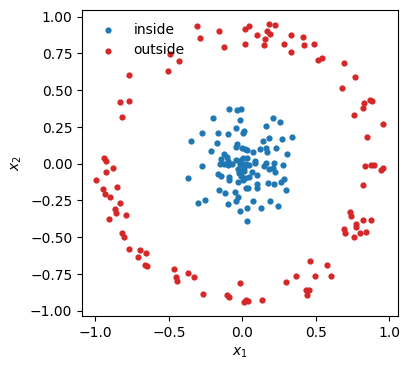

In [15]:
def circle_data(n=200, radius=1.0, noise=0.001, seed=13):
    rng = np.random.default_rng(seed)
    rows = np.zeros((n, 3))
    for i in range(n // 2):
        r = rng.uniform(0, radius * 0.4)
        angle = rng.uniform(0, 2 * np.pi)
        rows[i, 1] = r * np.sin(angle) + rng.uniform(-radius, radius) * noise
        rows[i, 2] = r * np.cos(angle) + rng.uniform(-radius, radius) * noise
    for i in range(n // 2, n):
        r = rng.uniform(radius * 0.8, radius)
        angle = rng.uniform(0, 2 * np.pi)
        rows[i, 0] = 1
        rows[i, 1] = r * np.sin(angle) + rng.uniform(-radius, radius) * noise
        rows[i, 2] = r * np.cos(angle) + rng.uniform(-radius, radius) * noise
    return rows

circle = circle_data()
x1, x2, y = circle[:, 1], circle[:, 2], circle[:, 0]
X = np.column_stack([x1, x2])

fig, ax = plt.subplots(figsize=(4.2, 4.2))
for label, color, name in ((0, 'C0', 'inside'), (1, 'C3', 'outside')):
    ax.scatter(x1[y == label], x2[y == label], s=12, c=color, label=name)
ax.set_aspect('equal')
ax.set_xlabel(r'$x_1$')
ax.set_ylabel(r'$x_2$')
ax.legend(frameon=False)
fig.tight_layout()

- Points inside a circle, and points outside it. No straight line separates the two groups.


True


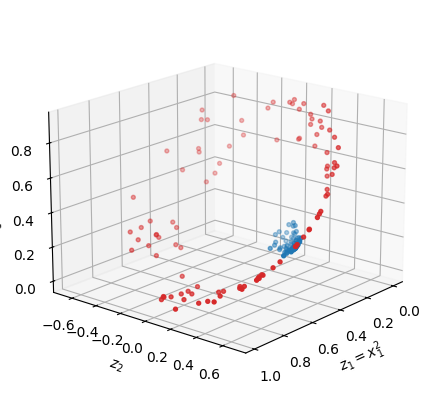

In [16]:
def phi(x1, x2):
    return np.column_stack([x1**2, np.sqrt(2) * x1 * x2, x2**2])

Z = phi(x1, x2)
# The kernel replaces the mapped inner product.
print(np.allclose(Z @ Z.T, (X @ X.T) ** 2))

fig = plt.figure(figsize=(5.2, 4.2))
ax = fig.add_subplot(111, projection='3d')
for label, color in ((0, 'C0'), (1, 'C3')):
    ax.scatter(Z[y == label, 0], Z[y == label, 1], Z[y == label, 2], s=8, c=color)
ax.set_xlabel(r'$z_1 = x_1^2$')
ax.set_ylabel(r'$z_2$')
ax.set_zlabel(r'$z_3 = x_2^2$')
ax.view_init(elev=18, azim=40)
fig.tight_layout()

- The map is

$$
\phi(x_1, x_2) = \bigl(x_1^2,\; \sqrt{2}\, x_1 x_2,\; x_2^2\bigr).
$$

- A flat plane in these new coordinates can separate the two groups. Drawn back in the original $x$, that plane is

$$
\omega_1 x_1^2 + \omega_2 \sqrt{2}\, x_1 x_2 + \omega_3 x_2^2 + b = 0,
$$

a closed curve around the inner cloud when the squared terms bend the right way and $b<0$.
- The check prints `True`: $\phi(a)^\top\phi(b) = (a^\top b)^2$. That square is the polynomial kernel. It lets you fill in the product for every pair of points without ever storing $\phi(x)$.


A logistic regression on $(x_1, x_2)$ is a straight line. The same regression on $\phi(x)$ is the curve. The two groups do not overlap, so a fit with no penalty would push the coefficients off to infinity. Both fits below use the same penalty. Guess the two accuracies before you run the cell.


line 0.525
phi  1.000


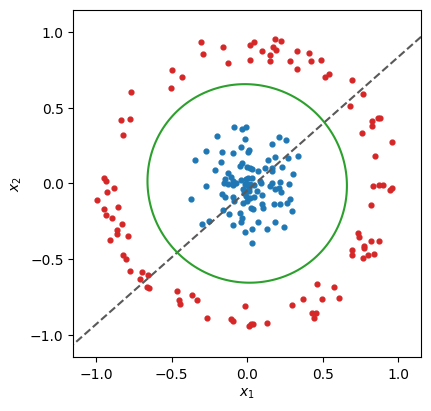

In [17]:
from sklearn.linear_model import LogisticRegression

line = LogisticRegression().fit(X, y)
curve = LogisticRegression().fit(Z, y)
print(f"line {line.score(X, y):.3f}")
print(f"phi  {curve.score(Z, y):.3f}")

grid = np.linspace(-1.15, 1.15, 250)
xx, yy = np.meshgrid(grid, grid)
fig, ax = plt.subplots(figsize=(4.4, 4.4))
for label, color in ((0, 'C0'), (1, 'C3')):
    ax.scatter(x1[y == label], x2[y == label], s=12, c=color)
zz = phi(xx.ravel(), yy.ravel())
ax.contour(xx, yy, line.decision_function(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape), levels=[0], colors='0.35', linestyles='--')
ax.contour(xx, yy, curve.decision_function(zz).reshape(xx.shape), levels=[0], colors='C2')
ax.set_aspect('equal')
ax.set_xlabel(r'$x_1$')
ax.set_ylabel(r'$x_2$')
fig.tight_layout()

- Both fits use the same penalty. The groups do not overlap, so a fit with no penalty would send the coefficients off to infinity.
- The straight line is right about 53% of the time. The fit on $\phi(x)$ is right every time.
- The dashed curve is the straight line. The green curve is the plane in the new coordinates, drawn back in $x$.
- Moving the cutoff moves the green curve. It does not turn the dashed line into a circle.


## 5. Betting

The Hong Kong pool sets a dividend on every horse. Money goes into one pool, and a horse that attracts more of it pays a smaller dividend. The dividend $O$ is what a winning \$1 ticket returns, and that return already includes the \$1 stake.

$1/O$ is the chance at which a bet on that horse alone breaks even: you pay \$1 and receive $O$ if it wins. Add $1/O$ over the horses in the race and the sum is larger than 1. The extra is the track's take, $1 - 1/\sum(1/O)$, about 17.5% in Hong Kong. Divide each $1/O$ by that sum and the shares add to 1. Those shares are the crowd's probabilities. The favorite is the horse with the largest share.

The take is a known cut, not a mistake in the crowd's ranking. After the shares add to 1, a favorite still wins more often than its share, and a longshot wins less often. That gap is the mispricing.

Benter estimated his own probability for every horse from three ingredients. The crowd's probabilities. One number $\alpha$: multiply the log-odds of each crowd probability by $\alpha$, then turn the results back into probabilities that add to 1. Above 1, $\alpha$ moves probability off the longshots and onto the favorite. The Hong Kong fit is 1.06. Then the jockey, the trainer, the draw, and the rating. Exactly one horse wins, so the final probabilities add to 1.

Call his probability $c$. The horse is mispriced when $c \times O > 1$. A \$1 ticket then has expected profit $c O - 1$. He bet every horse that passed that test, so a race could produce a bet on a horse that was not the favorite. The stake was the Kelly fraction of his bankroll, the share that maximizes the expected log of his wealth.

Here we drop the other horses. One row per race, the favorite only, and the question is whether that horse won more often than the crowd's probability.


### The problem

The crowd's price is not his chance. The problem is to calculate his own chance $c$ for every horse. The bet and the stake both use that number: bet when $c \times O > 1$. Here we calculate it only for the favorite.

### The data

5,885 Hong Kong races, 1997 to 2005. Each row is that race's favorite: the crowd's chance it wins, and whether it won.

### The model

The crowd's chance is the quoted price, turned into $1/O$ and scaled so the horses in a race add to 1. Logistic regression links that chance to the result. One number, $\alpha$, moves probability toward the favorite.

### The fit

Favorites win 4.7 percentage points more often than the crowd's chance: 4.3 at Happy Valley and 4.9 at Sha Tin. The fitted $\alpha$ is 1.06, so probability moves from the longshots onto the favorite.

- The quoted price is $O$. A winning \$1 ticket pays $O$, including the \$1 you paid. You break even when the chance of winning times $O$ equals 1, so that chance is $1/O$.
- Compute $1/O$ for a horse quoted at 3.5.


In [18]:
O = 3.5
print(1 / O)


0.2857142857142857


- $1/3.5 = 0.286$. Taken by itself, this bet breaks even if the horse wins 28.6% of the time.
- Do the same for every horse in the race and add those numbers. The sum is larger than 1. The extra is the track's take, $1 - 1/\sum(1/O)$. Hong Kong keeps about 17.5%.
- Divide each $1/O$ by that sum. The results add to 1. Those are the public probabilities. The favorite is the horse with the largest one.
- How far the favorite's win rate sits above its public probability is computed from the favorites file, under the favorite model. The plot there puts the public probability on the horizontal axis and the model's chance on the vertical axis. The dashed line is where those two would be equal.
- $\alpha$ is one number applied to the public probabilities. Above 1, it moves probability from the longshots onto the favorite. The formula is in the next section. The Hong Kong fit is $\alpha = 1.06$.
- In section 1 of the lab, read off how far the favorite's win rate sits above its public probability, the fitted $\alpha$, and the track's take.


### A race is the same softmax

- $K$ horses, and exactly one of them wins. This is not $K$ separate yes-or-no questions.
- The public probabilities in the example are $0.40, 0.30, 0.20, 0.10$.
- The model uses only those probabilities. It turns each one into a log-odds, multiplies by $\alpha$, and turns the results back into probabilities that sum to 1 inside the race:

$$
c_i = \frac{\exp(\alpha \,\mathrm{logit}\, p_i)}{\sum_{k} \exp(\alpha \,\mathrm{logit}\, p_k)}.
$$

- Before you run: at $\alpha=1$, is $c$ the same as $p$? At $\alpha=1.06$, which horse gains?


In [12]:
p = np.array([0.40, 0.30, 0.20, 0.10])
logit = np.log(p / (1 - p))

def field(alpha):
    score = alpha * logit
    score = score - score.max()
    w = np.exp(score)
    return w / w.sum()

print(np.round(field(1), 3))
print(np.round(field(1.06), 3))

[0.458 0.294 0.172 0.076]
[0.47  0.294 0.166 0.07 ]


- $\alpha=1$ gives the public probabilities back only when the race has two horses. With three or more, turning log-odds back through softmax moves the probabilities even at $\alpha=1$.
- $\alpha>1$ widens the gaps. Probability moves from the longshots to the favorite.
- In the Hong Kong case study, $\alpha$ is 1.06.
- The full Benter model adds the jockey, the trainer, the draw, and the rating, and then uses this same softmax.
- The penalty is $-\log c$ for the horse that won.


### The favorite model

In [19]:
races = pd.read_csv(DATA / 'hkjc-favorites.csv', parse_dates=['date'])
print(f"{len(races)} races, {races.date.min().date()} to {races.date.max().date()}")
print(f"win rate {races.win.mean():.3f}, mean public probability {races.public_prob.mean():.3f}")
names = {'HV': 'Happy Valley', 'ST': 'Sha Tin'}
for venue, part in races.groupby('venue'):
    gap = part.win.mean() - part.public_prob.mean()
    print(f"{names[venue]}: win {part.win.mean():.3f}, public {part.public_prob.mean():.3f}, gap {gap:.3f}")
races.head()


5885 races, 1997-11-30 to 2005-08-28
win rate 0.299, mean public probability 0.252
Happy Valley: win 0.281, public 0.237, gap 0.043
Sha Tin: win 0.309, public 0.260, gap 0.049


,race_id,date,venue,field_size,public_prob,win
0,460,1997-11-30,ST,14,0.265077,0
1,461,1997-11-30,ST,14,0.282162,1
2,462,1997-11-30,ST,11,0.330087,1
3,463,1997-11-30,ST,14,0.153291,1
4,464,1997-11-30,ST,14,0.210290,1


In [20]:
horse = smf.logit('win ~ public_prob', data=races).fit(disp=0)
horse.summary2().tables[1]

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
Intercept,-2.418935,0.111624,-21.670337,3.908812e-104,-2.637714,-2.200155
public_prob,6.099266,0.413218,14.760399,2.637141e-49,5.289373,6.909159


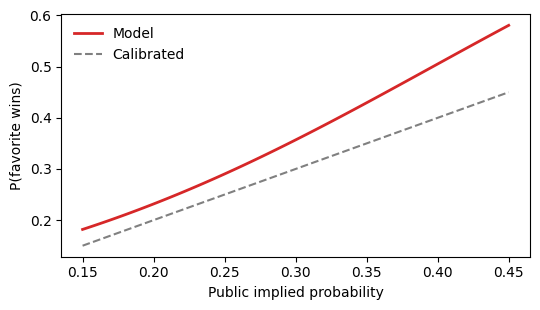

In [21]:
grid = np.linspace(0.15, 0.45, 100)
curve = horse.predict(pd.DataFrame({'public_prob': grid}))
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(grid, curve, color='C3', lw=2, label='Model')
ax.plot([0.15, 0.45], [0.15, 0.45], color='0.5', ls='--', label='Calibrated')
ax.set_xlabel('Public implied probability')
ax.set_ylabel('P(favorite wins)')
ax.legend(frameon=False)
fig.tight_layout()

- One row per race: the horse with the highest public probability. 5,885 races, 1997 to 2005. Those public probabilities average 0.252, and the horses win 0.299 of the races. The gap is 4.7 percentage points: 4.3 at Happy Valley and 4.9 at Sha Tin.
- Logistic regression of `win` on `public_prob`.
- In the plot, the curve is the model's chance that the favorite wins. A point on the dashed line would mean that chance equals the public probability. The curve is above the line.


t = 0.3: sensitivity 0.502, false positive rate 0.340
t = 0.5: sensitivity 0.074, false positive rate 0.026


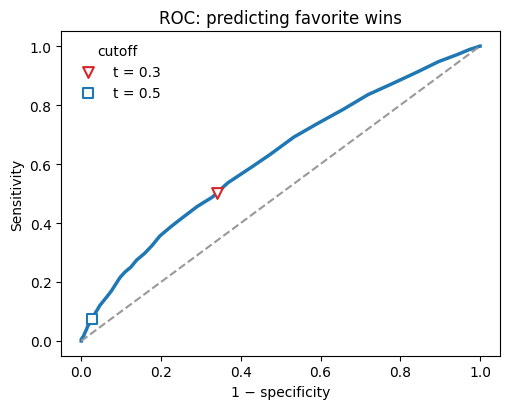

In [22]:
def roc(p, y, n_grid=100):
    p = np.asarray(p, dtype=float)
    y = np.asarray(y)
    t = np.linspace(0, 1, n_grid)
    # one column per cutoff: predict a win when p > t
    call = p[:, None] > t[None, :]
    specificity = np.mean(~call[y == 0], axis=0) if np.any(y == 0) else np.ones(n_grid)
    sensitivity = np.mean(call[y == 1], axis=0) if np.any(y == 1) else np.zeros(n_grid)
    return t, sensitivity, specificity

pred = horse.predict(races)
t, sensitivity, specificity = roc(pred, races.win.to_numpy())

def point(pred, y, t):
    y = np.asarray(y)
    # the book's marked points: losses with p < t, wins with p > t
    x = 1 - np.mean(pred[y == 0] < t)
    sens = np.mean(pred[y == 1] > t)
    return x, sens

fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.plot(1 - specificity, sensitivity, color='C0', lw=2.5)
ax.plot([0, 1], [0, 1], color='0.6', ls='--')
for t_mark, marker, color in ((0.3, 'v', 'C3'), (0.5, 's', 'C0')):
    x, sens = point(pred.to_numpy(), races.win.to_numpy(), t_mark)
    ax.scatter([x], [sens], marker=marker, s=60, facecolors='white', edgecolors=color, linewidths=1.5, label=f't = {t_mark}', zorder=3)
    print(f't = {t_mark}: sensitivity {sens:.3f}, false positive rate {x:.3f}')
ax.set_xlabel('1 − specificity')
ax.set_ylabel('Sensitivity')
ax.set_title('ROC: predicting favorite wins')
ax.legend(frameon=False, title='cutoff')
fig.tight_layout()

- The curve is built the same way as for the loans. Here the event is that the favorite wins.
- At $t=0.3$, close to the 30% win rate: the rule catches about half of the winning favorites, and it also bets on about 34% of the losing ones.
- At $t=0.5$: it catches about 7% of the winning favorites and bets on about 3% of the losing ones. Most favorite probabilities sit near 0.25, so a cutoff of one half bets on almost nobody.
- In Chapter 13 a winning \$1 bet pays 1.5 in profit and a losing bet costs 1. Expected profit uses the two numbers you just read off the curve:

$$
\mathrm{E}(\mathrm{profit}\mid t) = P(\mathrm{win})\cdot\mathrm{sensitivity}(t)\cdot 1.5 - P(\mathrm{lose})\cdot(1-\mathrm{specificity}(t))\cdot 1.
$$

- Profit 1.5 on a win and loss 1 on a loss means the cutoff that matches those costs is $t = 1/(1+1.5) = 0.4$. The book's check of these same races finds the best cutoff at 0.40.
- In the logistic lab, the NBA model at $t=0.5$ calls every favorite a win, so it never correctly skips a loser. There is no intercept, and a favorite's point spread is positive, so $p=\sigma(0.156\times\mathrm{spread})$ is always above $1/2$. Move the cutoff to 0.75 and read the new point.


### The stake

- Kelly's fraction is the share of your money that maximizes the expected log of wealth after the bet.
- For a bet that pays 1 to 1 and wins with probability $p$, that share is $p-(1-p)$. At $p=0.55$ it is 0.10: bet 10% of what you have.
- A bet that pays $b$ to 1:

$$
f^\star = \frac{bp-(1-p)}{b}.
$$

- The growth of log wealth per bet is $g(f)=p\log(1+bf)+(1-p)\log(1-f)$. It falls once you bet more than $f^\star$. Near twice $f^\star$, growth is about zero when the expected profit per dollar is small.
- The lab's two bets: $4/1$ at $p=1/4$, and $12/1$ at $p=1/10$. Which has the larger expected profit per dollar, and which has the larger stake?


In [23]:
def kelly(b, p):
    edge = b * p - (1 - p)
    return edge, edge / b

for b, p in ((4, 0.25), (12, 0.10)):
    edge, f = kelly(b, p)
    print(b, p, round(edge, 3), round(f, 4))

4 0.25 0.25 0.0625
12 0.1 0.3 0.025


- $4/1$ at $p=1/4$: expected profit 0.25 per dollar bet, so the stake is $1/16$ of your money.
- $12/1$ at $p=1/10$: expected profit 0.30 per dollar bet, so the stake is 0.025 of your money.
- The $12/1$ bet has the larger profit per dollar and a stake 2.5 times smaller.
- In section 4 of the lab, set the stake to twice $f^\star$ and guess the median growth of log wealth before you run the paths.
- In section 6, bet the same dollar amount on every race and lower the track's cut until that rule breaks even. The cut at which it breaks even is below the 17.5% Hong Kong keeps.
- That profit per dollar has to survive your own bet moving the price, and it has to show up in races the model was not fit on.
